# Wearable Technology: Fatigue and Drowsiness Risk Detection
**Goal:** identify *possible fatigue risk* (Low / Moderate / High) from **heart rate, movement and sleep-related data**.
**Use case:** workplace safety and driver-fatigue research.

**Important:** no real wearable recordings were available, so the data is **simulated** (see `src/generate_data.py`). The results show that the pipeline works, **not** how accurate it would be on real people. This is a research prototype, not a medical or safety device.

In [1]:
import sys
sys.path.insert(0, "src")
import warnings; warnings.filterwarnings("ignore")
import matplotlib.pyplot as plt, numpy as np, pandas as pd
from sklearn.metrics import classification_report
import fatigue_core as core, train_model as tm
%matplotlib inline
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
df = pd.read_csv(core.DATA_FILE)
print(df.shape, "-", df.subject_id.nunique(), "people,", len(df)//df.subject_id.nunique(), "windows each")
df.head()

(6000, 17) - 150 people, 40 windows each


,subject_id,shift_type,sleep_hours,sleep_efficiency,awakenings,sleep_debt_7d,hours_awake,shift_hours,hour_of_day,hr_mean,hr_resting,hrv_rmssd,hrv_baseline,activity_level,idle_min_per_hr,movement_var,fatigue_risk
0,1,night,5.23,87.8,2,5.19,15.18,6.88,5,68.1,57.8,57.4,60.3,252.8,13.9,0.423,Moderate
1,1,night,7.06,89.5,4,5.16,14.35,5.53,3,68.5,57.8,61.2,60.3,213.5,13.3,0.557,Low
2,1,night,6.73,88.7,4,7.29,11.01,7.80,5,65.2,57.8,47.9,60.3,253.3,11.9,0.381,Low
3,1,night,7.21,87.9,4,7.00,8.48,2.35,1,62.7,57.8,46.8,60.3,203.1,10.4,0.376,Low
4,1,night,5.56,89.4,3,7.84,11.82,2.83,0,72.2,57.8,52.9,60.3,178.4,13.7,0.484,Low


## 1. The data
Each row is one monitoring window of one person: sleep, work schedule, heart rate / HRV and movement. The label comes from a hidden fatigue score; the models only see the wearable signals.

In [2]:
print(df.fatigue_risk.value_counts(normalize=True).round(3).to_string())
df[core.RAW_COLUMNS].describe().T[["mean","std","min","max"]].round(2)

fatigue_risk
Low         0.588
Moderate    0.280
High        0.132


,mean,std,min,max
sleep_hours,6.66,1.36,2.50,10.00
sleep_efficiency,87.00,5.86,66.80,99.00
awakenings,2.65,2.27,0.00,15.00
sleep_debt_7d,7.19,4.58,0.00,22.81
hours_awake,9.50,4.02,1.54,21.66
shift_hours,6.23,3.31,0.50,12.00
hour_of_day,11.44,6.40,0.00,23.00
hr_mean,74.64,6.36,53.60,94.40
hr_resting,64.35,5.54,50.50,76.90
hrv_rmssd,47.58,14.01,14.30,113.70


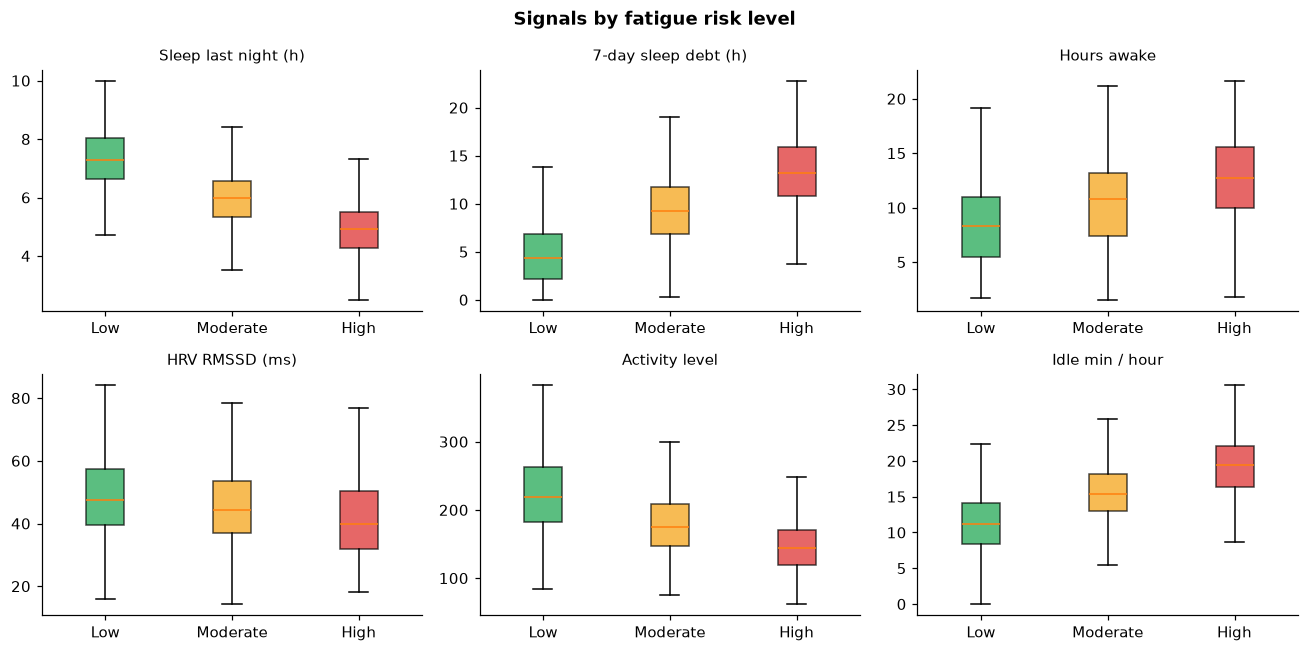

In [3]:
fig, axes = plt.subplots(2, 3, figsize=(12, 6))
order, colours = core.LABELS, {"Low":"#16a34a","Moderate":"#f59e0b","High":"#dc2626"}
for ax, col in zip(axes.ravel(), ["sleep_hours","sleep_debt_7d","hours_awake","hrv_rmssd","activity_level","idle_min_per_hr"]):
    data = [df.loc[df.fatigue_risk==l, col] for l in order]
    bp = ax.boxplot(data, tick_labels=order, patch_artist=True, showfliers=False)
    for patch, l in zip(bp["boxes"], order): patch.set_facecolor(colours[l]); patch.set_alpha(.7)
    ax.set_title(core.PRETTY.get(col, col) if col in core.PRETTY else "HRV RMSSD (ms)", fontsize=10)
fig.suptitle("Signals by fatigue risk level", fontweight="bold"); fig.tight_layout(); plt.show()

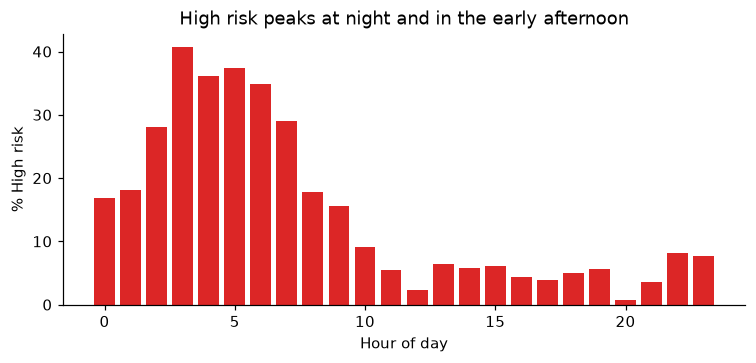

In [4]:
# time of day: share of High risk per hour (body-clock low points)
by_hour = df.groupby("hour_of_day").fatigue_risk.apply(lambda s: (s=="High").mean())
fig, ax = plt.subplots(figsize=(8, 3.2)); ax.bar(by_hour.index, by_hour.values*100, color="#dc2626")
ax.set_xlabel("Hour of day"); ax.set_ylabel("% High risk"); ax.set_title("High risk peaks at night and in the early afternoon"); plt.show()

## 2. Train and compare models
The split is **by person** (nobody is in both train and test), so the test score shows how the model works for *new* people. The best model is chosen by 5-fold cross-validation on the training people only. An explainable **rule-based score** is the baseline.

In [5]:
res = tm.train_and_evaluate()
res["table"]

Logistic Regression  CV macro-F1 0.799 +/- 0.015 | test acc 0.837  macro-F1 0.796  High recall 0.817


Random Forest        CV macro-F1 0.793 +/- 0.023 | test acc 0.846  macro-F1 0.794  High recall 0.721


Gradient Boosting    CV macro-F1 0.787 +/- 0.007 | test acc 0.843  macro-F1 0.791  High recall 0.726

Best model by cross-validation: Logistic Regression


,cv_macro_f1,accuracy,macro_f1,high_recall,high_precision
Rule-based score,NaN,0.814,0.752,0.579,0.864
Logistic Regression,0.799,0.837,0.796,0.817,0.759
Random Forest,0.793,0.846,0.794,0.721,0.807
Gradient Boosting,0.787,0.843,0.791,0.726,0.822


              precision    recall  f1-score   support

         Low      0.933     0.892     0.912       938
    Moderate      0.667     0.712     0.688       385
        High      0.759     0.817     0.787       197

    accuracy                          0.837      1520
   macro avg      0.786     0.807     0.796      1520
weighted avg      0.843     0.837     0.839      1520



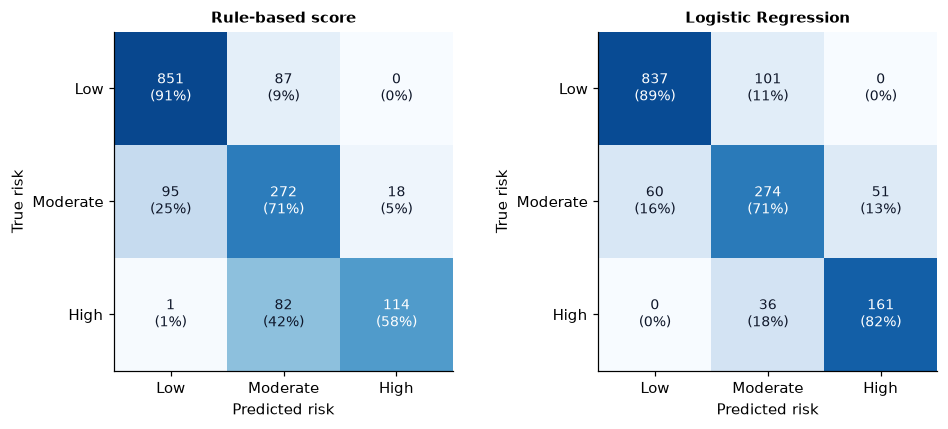

In [6]:
print(classification_report(res["y_test"], res["predictions"][res["best"]], labels=core.LABELS, digits=3))
fig, axes = plt.subplots(1, 2, figsize=(9, 4))
tm.plot_confusion(axes[0], res["y_test"], res["predictions"]["Rule-based score"], "Rule-based score")
tm.plot_confusion(axes[1], res["y_test"], res["predictions"][res["best"]], res["best"])
fig.tight_layout(); plt.show()

**Reading the result:** the ML model beats the rule baseline mainly on the *High* class (higher recall = fewer tired people missed). That matters most for safety: missing a fatigued driver is worse than a false alarm.

## 3. Which signals matter?

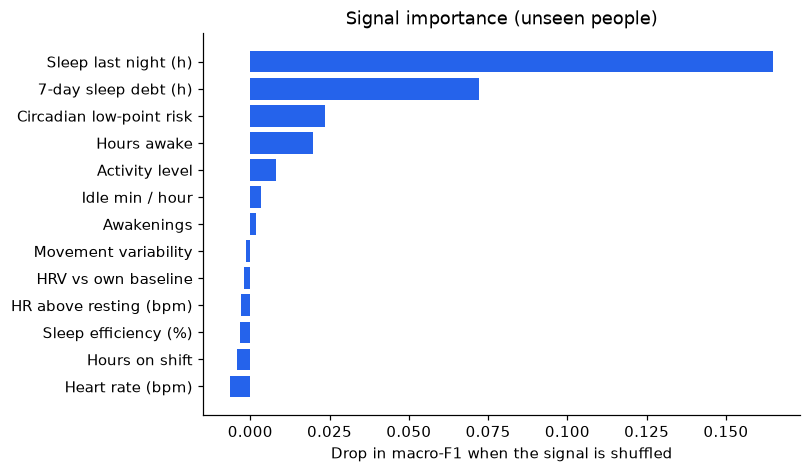

In [7]:
imp = res["importance"]
fig, ax = plt.subplots(figsize=(7, 4.5))
ax.barh([core.PRETTY[n] for n in imp.index], imp.values, color="#2563eb")
ax.set_xlabel("Drop in macro-F1 when the signal is shuffled"); ax.set_title("Signal importance (unseen people)"); plt.show()

,accuracy,macro_f1,high_recall,high_precision
Heart rate + HRV only,0.522,0.437,0.675,0.271
Movement only,0.673,0.616,0.706,0.521
Heart + Movement (body signals),0.686,0.628,0.716,0.540
Sleep only,0.776,0.714,0.721,0.693
Sleep + Schedule,0.824,0.780,0.802,0.756
All signals,0.837,0.796,0.817,0.759


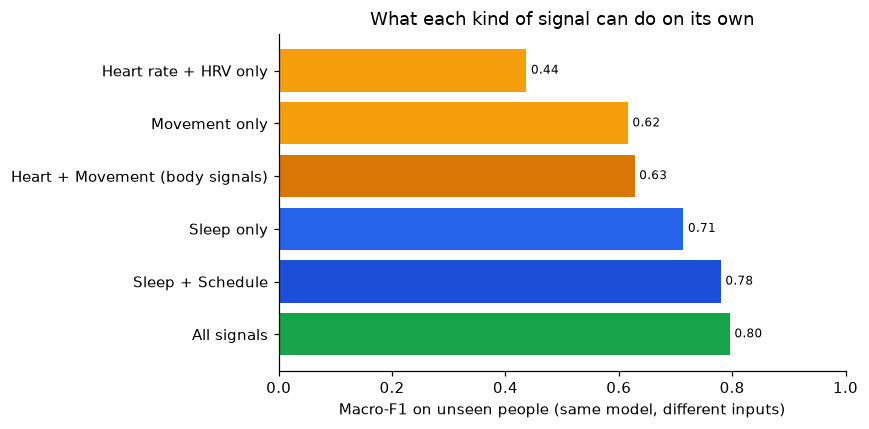

In [8]:
groups = tm.signal_group_comparison(res)
display(groups)
tm.plot_signal_groups(groups); plt.show()

**Finding:** on this simulated data, *sleep and schedule* carry most of the information. **Heart rate/HRV alone is weak (macro-F1 ~0.44)** and movement alone is moderate (~0.62); adding body signals to sleep and schedule gives only a small gain. Reason: in the simulation the body signals react only weakly and noisily to fatigue. Real wearables behave similarly: single-signal heart-rate methods are noisy, so combining sources is the sensible design. The exact numbers depend on how the data was simulated and must be re-measured on real recordings.

## 4. Limitations and ethics
* **Simulated data** - accuracy on real people is unknown; the next step is validation on real wearable data with a trusted reference (e.g. reaction-time tests such as PVT, or expert rating).
* The labels come from a model of fatigue, not from measured drowsiness, so there is some circularity: the model learns the simulator's rules.
* Fatigue is subjective and varies by person; baseline-relative features (HRV vs own normal) are used, but real use needs per-person calibration.
* Workers' physiological data is sensitive. A real deployment needs consent, data minimisation and rules that the output is used for safety support, **not** for discipline or surveillance.
* This tool must **support** safety measures (rest rules, supervisors), never replace them.

## 5. Try one person
The same function the desktop app (`src/fatigue_app.py`) uses.

In [9]:
import fatigue_app as app
model, note = app.load_model()
person = dict(sleep_hours=4.5, sleep_efficiency=72, awakenings=5, sleep_debt_7d=12, hours_awake=18, shift_hours=9,
              hour_of_day=3, hr_mean=68, hr_resting=63, hrv_rmssd=33, hrv_baseline=52,
              activity_level=100, idle_min_per_hr=26, movement_var=0.38)
probs = app.predict(model, person)
print({k: round(v, 2) for k, v in probs.items()}, "->", max(probs, key=probs.get))
pts, why = core.rule_score(person)
print("Rule score:", pts, core.rule_level(pts))
for p, t in why: print(" +%d  %s" % (p, t))
print("Advice:", core.ADVICE[max(probs, key=probs.get)])

{'Low': 0.0, 'Moderate': 0.0, 'High': 1.0} -> High
Rule score: 17 High
 +3  Short sleep last night (4.5 h)
 +2  Accumulated sleep debt (12.0 h this week)
 +2  Awake for a long time (18 h)
 +2  Body-clock low point (around 03:00)
 +2  HRV is 37 % below the person's normal
 +2  Very little movement (26 idle min / h)
 +1  Poor sleep quality (72 % efficiency)
 +1  Broken sleep (5 awakenings)
 +1  Long time on shift / at the wheel (9.0 h)
 +1  Low activity level
Advice: Stop safety-critical work or driving now. Rest or nap (15-20 min) in a safe place, tell a supervisor, and arrange a replacement or a safe ride. Do not rely on caffeine or open windows.
